# Multi-Class Benchmark Classification Pipeline (Iris)

A supervised classification pipeline that benchmarks **Logistic Regression** and a **Decision Tree** on the Iris dataset.

| Item | Details |
|------|---------|
| Dataset | Iris (150 samples, 4 features, 3 classes) |
| Models | Logistic Regression, Decision Tree |
| Preprocessing | `StandardScaler` (fitted on training data only) |
| Split | 80/20 stratified train/test |
| Metrics | Accuracy, Precision, Recall, F1-score (macro) |
| Validation | Hold-out test set + 5-fold cross-validation |

## Table of Contents
1. Setup and Imports
2. Data Loading and Quality Checks
3. Exploratory Data Analysis
4. Train/Test Split and Feature Scaling
5. Model Training
6. Model Benchmarking
7. Confusion Matrices
8. Decision Boundary Visualization
9. Cross-Validation
10. Summary and Conclusions

# **1- Setup and Imports**

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

print("Environment ready.")

Environment ready.


# **2- Upload and Load the CSV**

In [2]:
df = pd.read_csv("/content/iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


# **3- Data Quality Checks**

In [3]:
print(f"Dataset shape: {df.shape}\n")

print("Data types:")
print(df.dtypes, "\n")

print(f"Total missing values: {df.isnull().sum().sum()}")
print(f"Duplicated rows: {df.duplicated().sum()}\n")

print("Class distribution:")
print(df["species"].value_counts())

Dataset shape: (150, 5)

Data types:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object 

Total missing values: 0
Duplicated rows: 1

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


In [5]:
display(df[df.duplicated(keep=False)])

,sepal_length,sepal_width,petal_length,petal_width,species
101,5.8,2.7,5.1,1.9,virginica
142,5.8,2.7,5.1,1.9,virginica


# **4- Exploratory Pairplot**

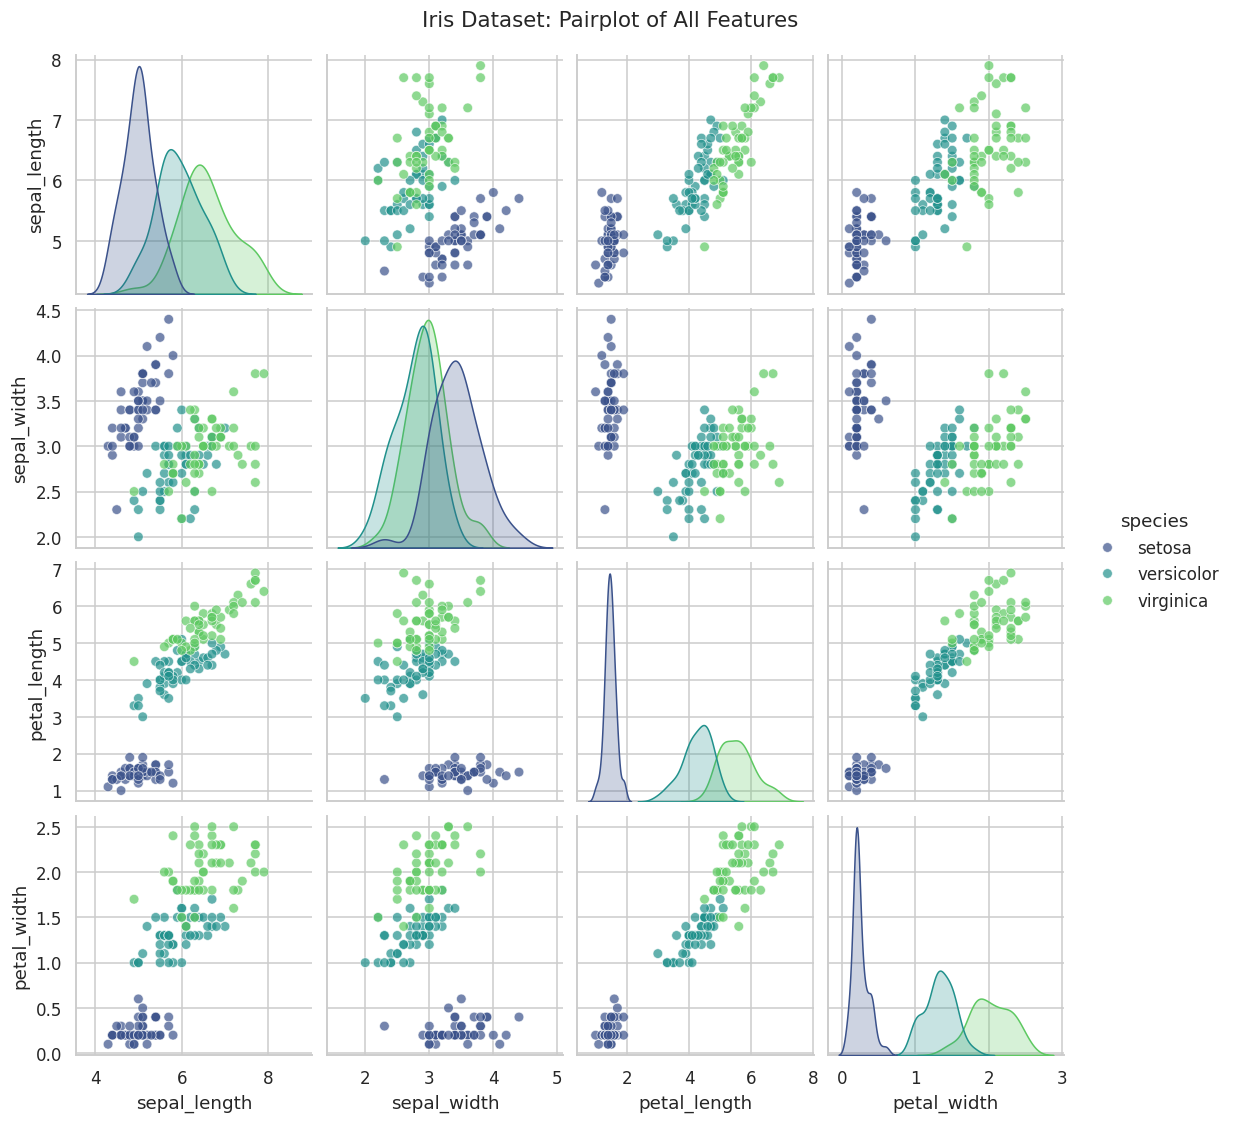

In [6]:
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

pairplot = sns.pairplot(
    df,
    vars=feature_cols,
    hue="species",
    palette="viridis",
    diag_kind="kde",
    plot_kws={"alpha": 0.7, "s": 40},
)
pairplot.fig.suptitle("Iris Dataset: Pairplot of All Features", y=1.02, fontsize=14)
plt.show()

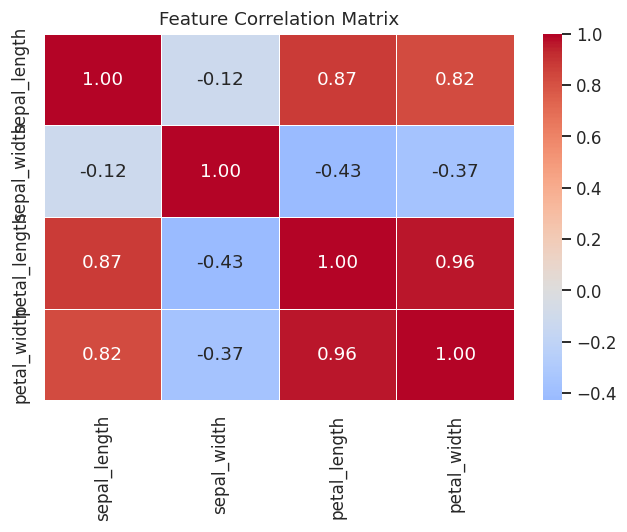

In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    df[feature_cols].corr(),
    annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5,
)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

# **5- Train/Test Split**

In [8]:
from sklearn.model_selection import train_test_split

X = df[feature_cols]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set:     {X_test.shape[0]} samples\n")

print("Train class distribution:")
print(y_train.value_counts(), "\n")
print("Test class distribution:")
print(y_test.value_counts())

Training set: 120 samples
Test set:     30 samples

Train class distribution:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64 

Test class distribution:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


# **6- Feature Scaling**

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

scaled_summary = pd.DataFrame(
    {
        "mean": X_train_scaled.mean(axis=0),
        "std": X_train_scaled.std(axis=0),
    },
    index=feature_cols,
)
display(scaled_summary.round(3))

,mean,std
sepal_length,-0.0,1.0
sepal_width,0.0,1.0
petal_length,0.0,1.0
petal_width,0.0,1.0


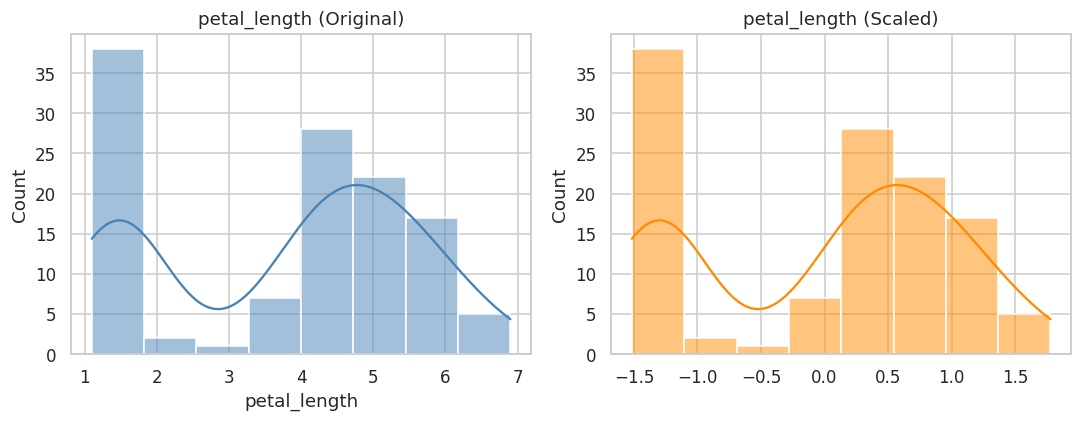

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(X_train["petal_length"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("petal_length (Original)")

sns.histplot(X_train_scaled[:, feature_cols.index("petal_length")], kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("petal_length (Scaled)")

plt.tight_layout()
plt.show()

# **7- Train the Models**

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

dec_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
dec_tree.fit(X_train_scaled, y_train)

models = {
    "Logistic Regression": log_reg,
    "Decision Tree": dec_tree,
}

for name, model in models.items():
    print(f"{name} - Train accuracy: {model.score(X_train_scaled, y_train):.4f}")

Logistic Regression - Train accuracy: 0.9583
Decision Tree - Train accuracy: 0.9833


# **8- Benchmark on the Test Set**

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
)

def evaluate_model(name, model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Precision": precision_score(y_eval, y_pred, average="macro"),
        "Recall": recall_score(y_eval, y_pred, average="macro"),
        "F1-Score": f1_score(y_eval, y_pred, average="macro"),
    }

results = pd.DataFrame(
    [evaluate_model(name, model, X_test_scaled, y_test) for name, model in models.items()]
).set_index("Model")

display(results.round(4).style.background_gradient(cmap="Greens", axis=None))

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.933300,0.933300,0.933300,0.933300
Decision Tree,0.966700,0.969700,0.966700,0.966600


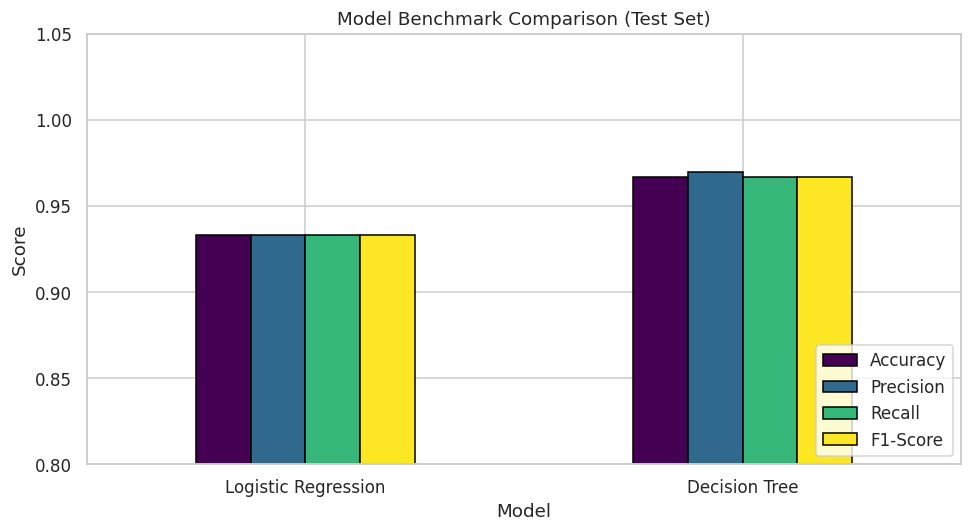

In [13]:
ax = results.plot(kind="bar", figsize=(9, 5), colormap="viridis", edgecolor="black")
ax.set_title("Model Benchmark Comparison (Test Set)")
ax.set_ylabel("Score")
ax.set_ylim(0.8, 1.05)
ax.legend(loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [15]:
for name, model in models.items():
    print(f"\n{'=' * 55}\n{name}\n{'=' * 55}")
    print(classification_report(y_test, model.predict(X_test_scaled)))


Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



# **9- Confusion Matrix Heatmaps**

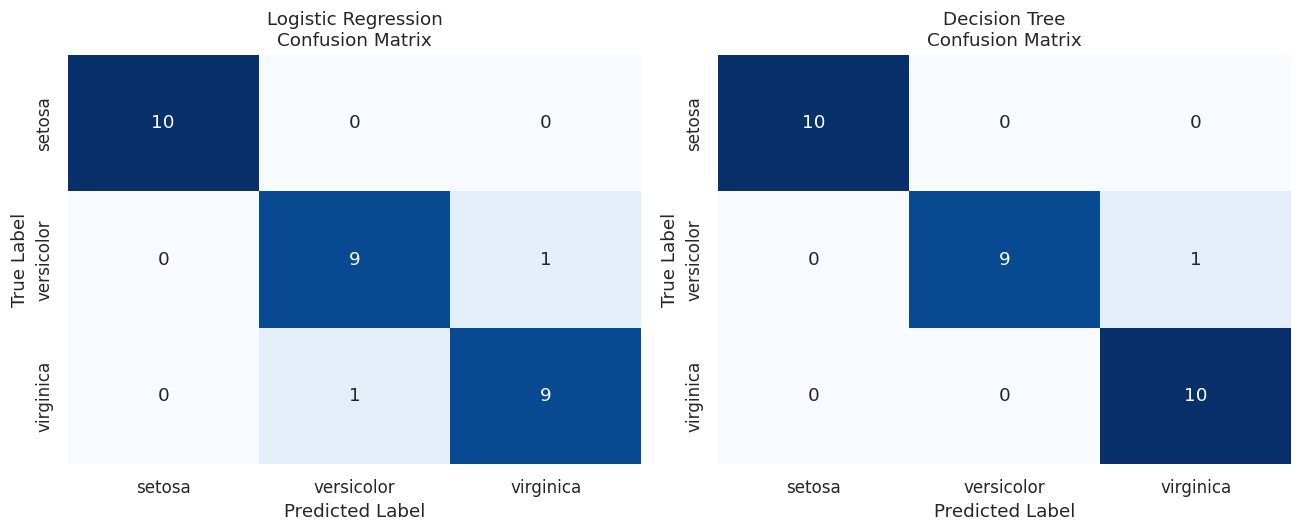

In [16]:
from sklearn.metrics import confusion_matrix

class_names = sorted(y.unique())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test_scaled), labels=class_names)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=class_names, yticklabels=class_names, ax=ax,
    )
    ax.set_title(f"{name}\nConfusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()

# **10- Decision Boundary Visualization**

In [17]:
viz_features = ["petal_length", "petal_width"]

scaler_2d = StandardScaler()
X_train_2d = scaler_2d.fit_transform(X_train[viz_features])
X_test_2d = scaler_2d.transform(X_test[viz_features])

viz_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}
for model in viz_models.values():
    model.fit(X_train_2d, y_train)

for name, model in viz_models.items():
    print(f"{name} - 2D test accuracy: {model.score(X_test_2d, y_test):.4f}")

Logistic Regression - 2D test accuracy: 0.9333
Decision Tree - 2D test accuracy: 0.9667


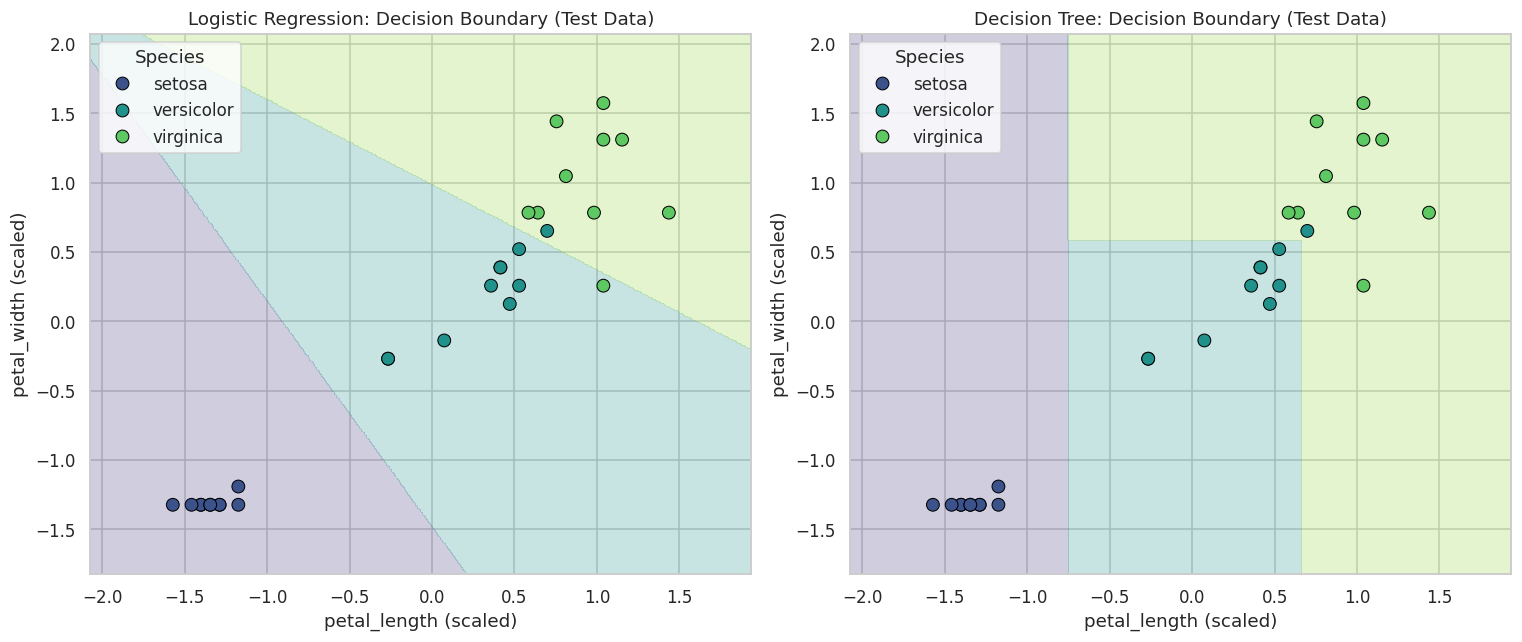

In [18]:
def plot_decision_boundary(model, X, y, ax, title, feature_names):
    classes = list(model.classes_)
    y_numeric = np.array([classes.index(label) for label in y])

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 400),
        np.linspace(y_min, y_max, 400),
    )

    grid_pred = model.predict(np.c_[xx.ravel(), yy.ravel()])
    grid_numeric = np.array([classes.index(label) for label in grid_pred]).reshape(xx.shape)

    ax.contourf(xx, yy, grid_numeric, alpha=0.25, cmap="viridis", levels=np.arange(-0.5, len(classes), 1))
    sns.scatterplot(
        x=X[:, 0], y=X[:, 1], hue=y, hue_order=classes,
        palette="viridis", edgecolor="black", s=70, ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel(f"{feature_names[0]} (scaled)")
    ax.set_ylabel(f"{feature_names[1]} (scaled)")
    ax.legend(title="Species", loc="best")


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (name, model) in zip(axes, viz_models.items()):
    plot_decision_boundary(
        model, X_test_2d, y_test.values, ax,
        f"{name}: Decision Boundary (Test Data)", viz_features,
    )

plt.tight_layout()
plt.show()

In [19]:
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    ),
    "Decision Tree": make_pipeline(
        StandardScaler(), DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
    ),
}

scoring = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]

cv_rows = []
for name, pipe in cv_models.items():
    scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    row = {"Model": name}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[metric] = f"{values.mean():.4f} ± {values.std():.4f}"
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).set_index("Model")
display(cv_results)

,accuracy,precision_macro,recall_macro,f1_macro
Model,,,,
Logistic Regression,0.9533 ± 0.0452,0.9549 ± 0.0443,0.9533 ± 0.0452,0.9532 ± 0.0453
Decision Tree,0.9600 ± 0.0249,0.9634 ± 0.0232,0.9600 ± 0.0249,0.9598 ± 0.0251


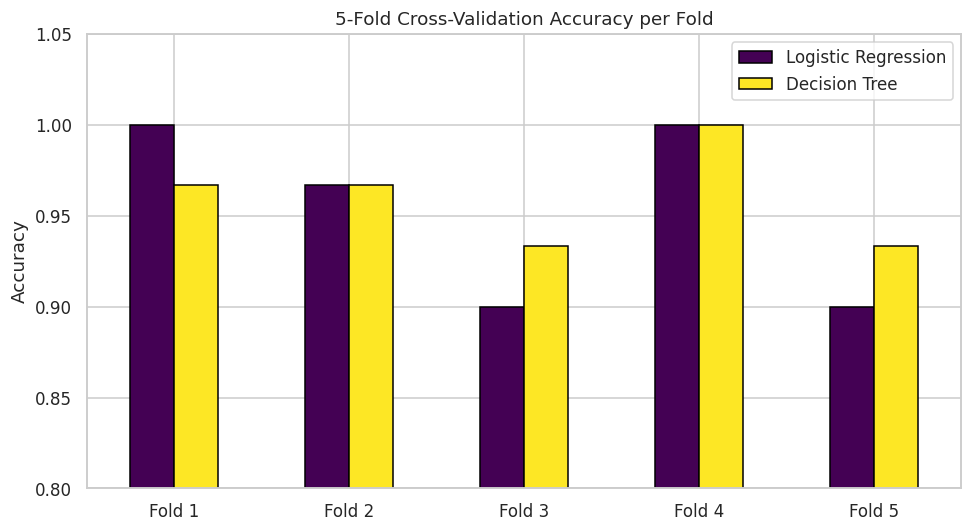

In [20]:
fold_scores = {
    name: cross_validate(pipe, X, y, cv=cv, scoring="accuracy")["test_score"]
    for name, pipe in cv_models.items()
}

fold_df = pd.DataFrame(fold_scores, index=[f"Fold {i}" for i in range(1, 6)])

ax = fold_df.plot(kind="bar", figsize=(9, 5), colormap="viridis", edgecolor="black")
ax.set_title("5-Fold Cross-Validation Accuracy per Fold")
ax.set_ylabel("Accuracy")
ax.set_ylim(0.8, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
summary = pd.DataFrame({
    "Hold-out Accuracy (n=30)": results["Accuracy"],
    "Hold-out F1 (macro)": results["F1-Score"],
    "CV Accuracy (mean)": fold_df.mean(),
    "CV Accuracy (std)": fold_df.std(ddof=0),
})

display(summary.round(4))

,Hold-out Accuracy (n=30),Hold-out F1 (macro),CV Accuracy (mean),CV Accuracy (std)
Logistic Regression,0.9333,0.9333,0.9533,0.0452
Decision Tree,0.9667,0.9666,0.9600,0.0249


# **Conclusions**

1. **Setosa is linearly separable.** Both models classify it perfectly. All
   errors occur between Versicolor and Virginica, which overlap in feature space.
2. **Petal features dominate.** `petal_length` and `petal_width` alone reproduce
   the full 4-feature test accuracy and give the cleanest class separation.
3. **No significant difference between the models.** Hold-out accuracy was 93.3%
   (Logistic Regression) vs. 96.7% (Decision Tree), a gap of one test sample.
   5-fold cross-validation narrows it to 95.3% ± 4.5% vs. 96.0% ± 2.5%, well within
   one standard deviation.
4. **The Decision Tree is more stable across folds**, while Logistic Regression
   produces smoother, linear decision boundaries and generalizes comparably.
5. **Limitations:** small dataset (150 samples, one duplicated row kept as in the
   original benchmark), `max_depth` was fixed rather than tuned, and a 30-sample
   test set makes single-split metrics noisy.